# Customer Churn Prediction

In this project I try to predict which telecom customers will leave (churn), and find out what makes customers leave.

**Dataset:** Telco Customer Churn (7,043 customers, 21 columns)

**Steps**
1. Load and clean the data
2. Explore the data (EDA)
3. Prepare the data for machine learning
4. Train and compare 3 models (Logistic Regression, Decision Tree, Random Forest)
5. Check for overfitting and improve the Random Forest
6. Look at the results and the most important features

## 1. Load and clean the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)



In [19]:
df = pd.read_csv("Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


`TotalCharges` is stored as text (object) instead of a number. This is because a few rows contain an empty space. Let's fix that.

In [21]:
# Convert TotalCharges to numbers (empty values become NaN)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Look at the rows with missing values
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]

Missing TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


All the missing rows have `tenure = 0`, so they are new customers who haven't been charged yet. So it makes sense to fill the missing values with 0.

In [23]:
df.loc[df["TotalCharges"].isnull(), "TotalCharges"] = 0
print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


## 2. Exploratory data analysis

### How many customers churn?

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


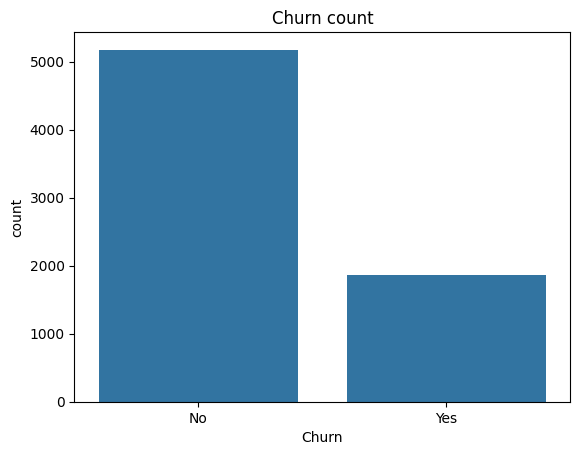

In [24]:
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True).round(3) * 100)

sns.countplot(data=df, x="Churn")
plt.title("Churn count")
plt.show()

About 27% of the customers churned, so the data is **imbalanced** (more customers stay than leave). I keep this in mind when training the models.

### Churn by contract type

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


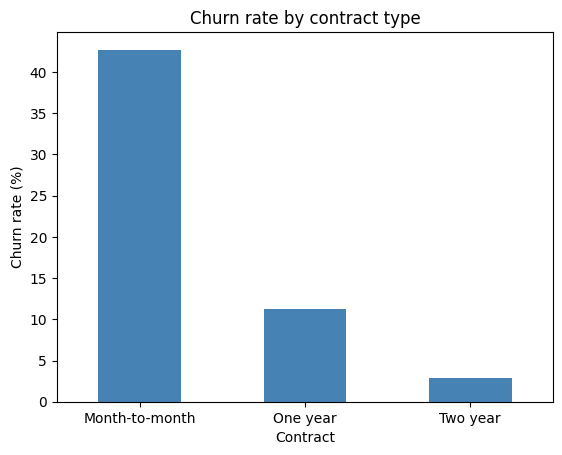

In [25]:
# Percentage of customers who churned in each contract type
contract_churn = df.groupby("Contract")["Churn"].apply(lambda x: (x == "Yes").mean() * 100)
print(contract_churn.round(1))

contract_churn.plot(kind="bar", color="steelblue")
plt.title("Churn rate by contract type")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=0)
plt.show()

### Churn and tenure (how long the customer has been with the company)

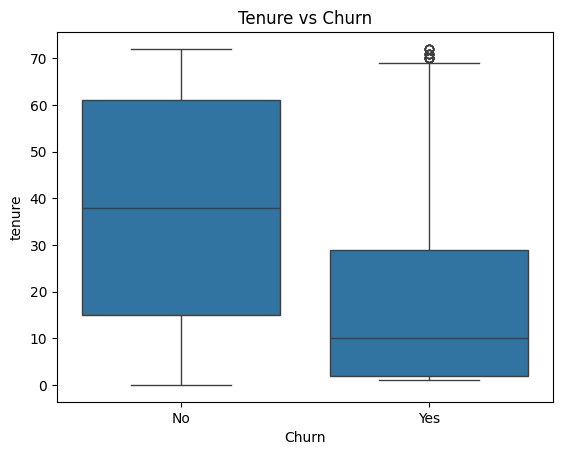

Average tenure (months):
Churn
No     37.6
Yes    18.0
Name: tenure, dtype: float64


In [26]:
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Tenure vs Churn")
plt.show()

print("Average tenure (months):")
print(df.groupby("Churn")["tenure"].mean().round(1))

### Churn and monthly charges

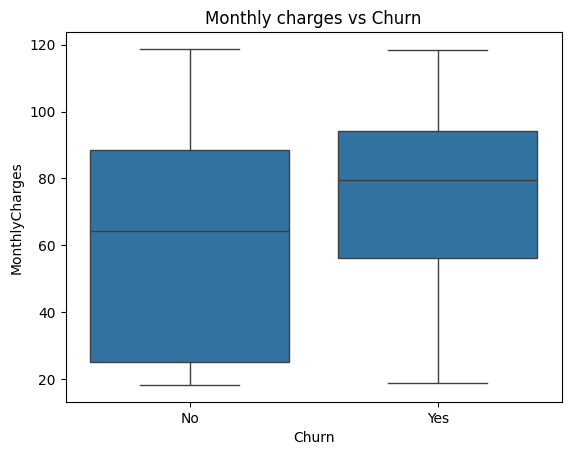

In [27]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly charges vs Churn")
plt.show()

### Churn by internet service

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn, dtype: float64


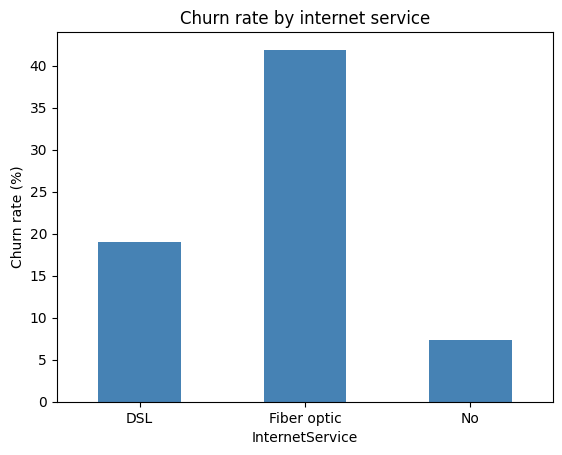

In [28]:
internet_churn = df.groupby("InternetService")["Churn"].apply(lambda x: (x == "Yes").mean() * 100)
print(internet_churn.round(1))

internet_churn.plot(kind="bar", color="steelblue")
plt.title("Churn rate by internet service")
plt.ylabel("Churn rate (%)")
plt.xticks(rotation=0)
plt.show()

**What I found in the EDA**
- **Contract type matters a lot:** month-to-month customers churn at 42.7%, one-year at 11.3% and two-year at only 2.8%.
- **New customers leave more:** churned customers had an average tenure of 18 months, compared to 37.6 months for customers who stayed.
- **Churners tend to pay more** per month (see the box plot).
- **Fiber optic customers churn the most** (41.9%), compared to DSL (19.0%) and customers with no internet service (7.4%).

## 3. Prepare the data for machine learning
- Remove `customerID` (it is just an ID, not useful for prediction)
- Convert the target `Churn` to numbers (No = 0, Yes = 1)
- Convert text columns to numbers using one-hot encoding (`pd.get_dummies`)
- Split into training (80%) and testing (20%) sets
- Scale the numeric columns

In [29]:
# Features (X) and target (y)
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Turn text columns into numbers
X = pd.get_dummies(X, drop_first=True)
print("Number of features after encoding:", X.shape[1])

Number of features after encoding: 30


In [31]:
# Split the data. stratify=y keeps the same churn percentage in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training set:", X_train.shape)
print("Testing set: ", X_test.shape)

Training set: (5634, 30)
Testing set:  (1409, 30)


In [32]:
# Scale the numeric columns (fit only on training data so the test data stays unseen)
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()

X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

## 4. Train and compare 3 models
I use `class_weight="balanced"` so the models pay more attention to the churners (the smaller group).

In [37]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12,
                                            class_weight="balanced", random_state=42),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
    })

results_df = pd.DataFrame(results).set_index("Model")
formatted_df = (results_df * 100).round(1).astype(str) + "%"
print(formatted_df)

                    Accuracy Precision Recall     F1 ROC-AUC
Model                                                       
Logistic Regression    73.8%     50.4%  78.3%  61.4%   84.2%
Decision Tree          73.8%     50.4%  81.8%  62.4%   82.6%
Random Forest          77.6%     56.5%  67.1%  61.4%   83.8%


Accuracy alone is not a good metric here because only 27% of customers churn. A model that says "nobody churns" would already get about 73% accuracy. So I also look at **recall** (how many churners we catch), **precision** (how many of the customers we flag really churn), **F1** and **ROC-AUC**.

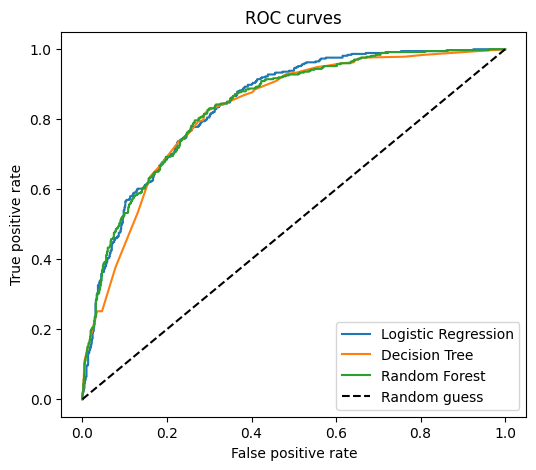

In [38]:
# Plot the ROC curves
plt.figure(figsize=(6, 5))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves")
plt.legend()
plt.show()

## 5. Is the model reliable? Cross-validation and overfitting
One test split can be lucky or unlucky, so I also use 5-fold cross-validation. I also compare the score on the training data with the score on the test data. If the training score is much higher, the model is **overfitting** (memorising the training data).

In [39]:
# 5-fold cross-validation (ROC-AUC) on the training data
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="roc_auc")
    print(f"{name:20s} mean AUC = {scores.mean():.3f}  (+/- {scores.std():.3f})")

Logistic Regression  mean AUC = 0.845  (+/- 0.014)
Decision Tree        mean AUC = 0.820  (+/- 0.012)
Random Forest        mean AUC = 0.840  (+/- 0.012)


In [40]:
# Compare training vs testing ROC-AUC
for name, model in models.items():
    train_auc = roc_auc_score(y_train, model.predict_proba(X_train)[:, 1])
    test_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
    print(f"{name:20s} train AUC = {train_auc:.3f} | test AUC = {test_auc:.3f}")

Logistic Regression  train AUC = 0.849 | test AUC = 0.842
Decision Tree        train AUC = 0.860 | test AUC = 0.826
Random Forest        train AUC = 0.972 | test AUC = 0.838


**What this shows**
- The **Random Forest is overfitting**: its train AUC is 0.972 but its test AUC is only 0.838. It memorised the training data.
- Logistic Regression has almost the same train and test score (0.849 vs 0.842), so it generalises well.
- In cross-validation the three models are close (Logistic Regression 0.845, Random Forest 0.840, Decision Tree 0.820). The differences are small compared to the spread between folds, so I can't say one model is clearly the best.

### Improving the Random Forest
I use `GridSearchCV` to try a few settings for the Random Forest. Smaller `max_depth` and bigger `min_samples_leaf` make the trees simpler, which should reduce overfitting.

In [42]:
param_grid = {
    "max_depth": [4, 6, 8, 12],
    "min_samples_leaf": [1, 5, 10, 20],
}

grid = GridSearchCV(
    RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=40),
    param_grid, cv=5, scoring="roc_auc", n_jobs=-1
)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best CV ROC-AUC:", round(grid.best_score_, 3))

Best settings: {'max_depth': 12, 'min_samples_leaf': 20}
Best CV ROC-AUC: 0.847


In [43]:
best_rf = grid.best_estimator_

train_auc = roc_auc_score(y_train, best_rf.predict_proba(X_train)[:, 1])
test_auc = roc_auc_score(y_test, best_rf.predict_proba(X_test)[:, 1])
print(f"Tuned Random Forest: train AUC = {train_auc:.3f} | test AUC = {test_auc:.3f}")

pred = best_rf.predict(X_test)
print()
print("Accuracy :", round(accuracy_score(y_test, pred), 3))
print("Precision:", round(precision_score(y_test, pred), 3))
print("Recall   :", round(recall_score(y_test, pred), 3))
print("F1       :", round(f1_score(y_test, pred), 3))

Tuned Random Forest: train AUC = 0.880 | test AUC = 0.845

Accuracy : 0.757
Precision: 0.528
Recall   : 0.791
F1       : 0.633


**After tuning**
- The best settings were `max_depth=12` and `min_samples_leaf=20`. The depth is the same as before, so the improvement comes from `min_samples_leaf=20`: each leaf must contain at least 20 customers, which stops the trees from memorising tiny groups.
- The gap between train and test AUC became much smaller (0.880 vs 0.845, before it was 0.972 vs 0.838), so the overfitting is mostly fixed, and the test AUC improved slightly from 0.838 to 0.845.
- Recall went from 0.671 to 0.791, so the model now catches about 79% of the customers who churn. The price is lower precision (0.53): almost half of the customers it flags would have stayed anyway.

## 6. Results of the tuned Random Forest
### Confusion matrix

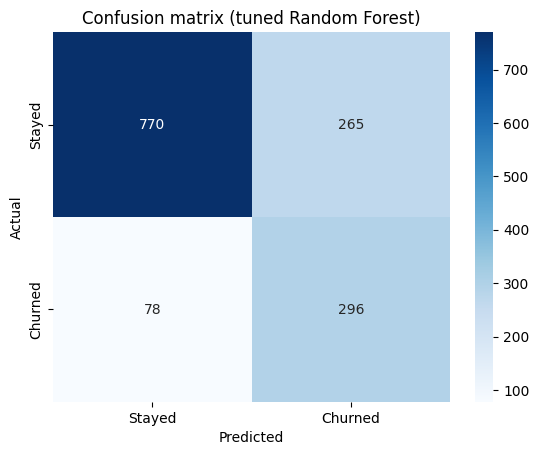

In [44]:
cm = confusion_matrix(y_test, best_rf.predict(X_test))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix (tuned Random Forest)")
plt.show()

### Changing the threshold
By default a customer is predicted as "churn" if the probability is above 0.5. A lower threshold catches more churners (higher recall) but also flags more customers who would have stayed (lower precision). This table shows the trade-off.

In [45]:
probs = best_rf.predict_proba(X_test)[:, 1]

rows = []
for t in [0.3, 0.4, 0.5, 0.6]:
    pred = (probs >= t).astype(int)
    rows.append({"Threshold": t,
                 "Customers flagged": int(pred.sum()),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})

pd.DataFrame(rows).set_index("Threshold").round(3)

,Customers flagged,Precision,Recall,F1
Threshold,,,,
0.3,792,0.424,0.898,0.576
0.4,691,0.466,0.861,0.605
0.5,561,0.528,0.791,0.633
0.6,428,0.596,0.682,0.636


Lowering the threshold to 0.3 catches 90% of the churners but flags 792 customers, and only 42% of them really churn. Raising it to 0.6 gives better precision (59.6%) but misses more churners. Which threshold is best depends on the business: if a retention offer is cheap compared to losing a customer, a lower threshold makes sense.

*(Note: this table is only to show the trade-off. In a real project the threshold should be chosen using validation data, not the test set.)*

### Which features matter most?

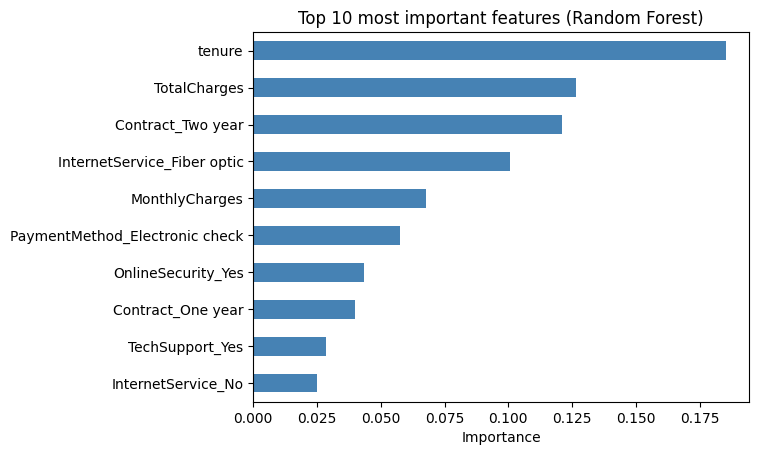

In [46]:
importances = pd.Series(best_rf.feature_importances_, index=X_train.columns)
top10 = importances.sort_values(ascending=False).head(10)

top10.sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 most important features (Random Forest)")
plt.xlabel("Importance")
plt.show()

The most important features are **tenure**, **TotalCharges**, **Contract_Two year** and **fiber optic internet**, followed by **MonthlyCharges** and **electronic check payment**. This matches what I saw in the EDA. (Random Forest importance can favour numeric columns like tenure and charges, so I treat this as a rough guide, not exact numbers.)

## 7. Conclusion

**What I learned about churn**
- Customers on **month-to-month contracts**, **new customers** (low tenure), customers with **fiber optic internet** and customers paying by **electronic check** are the most likely to churn.
- Long-term customers with one- or two-year contracts rarely leave.

**About the models**
- All three models reached a ROC-AUC of about 0.82-0.85, and the differences between them were small.
- The first Random Forest was overfitting. Requiring at least 20 customers in each leaf fixed most of this and improved recall from 67% to 79%.
- The final tuned Random Forest has a test ROC-AUC of 0.845, with 79% recall and 53% precision.

**Suggestions for the company**
- Offer discounts or benefits to move month-to-month customers to longer contracts.
- Pay extra attention to customers in their first months.
- Look into why fiber optic and electronic check customers leave more often.

**Limitations and ideas for the future**
- The dataset is a single snapshot, so I can't tell how the model would work on future customers.
- This analysis shows relationships, not proof of what causes churn.
- Things I could try next: other models like XGBoost, and explaining individual predictions with SHAP.